# Network PPO — Réseau, décisions et efficacité

Explorer les anciens scénarios factory conservés sous `instances/legacy/` et mesurer ce que servent réellement les décisions.

Depuis la racine du repo : `python -m pip install -e '.[notebook]' (ajouter l’extra `rl` pour PPO)`, puis
`python -m jupyterlab notebook/network_and_efficiency.ipynb` et **Run All**.

Ce notebook fonctionne **sans entraînement** : il trace la topologie et calcule une
initialisation faisable ainsi qu'une référence gloutonne sur les 11 scénarios synthétiques.
Pour comparer PPO, entraîner le modèle avec `python train.py --instances instances/legacy/train --output outputs/ppo_factory`, puis activer `RUN_PPO`
dans la cellule de configuration. L'évaluation est relancée sur le scénario sélectionné ;
aucun ancien fichier de décision n'est utilisé implicitement.

**Efficacité = somme des Mbps servis / somme des Mbps maximum demandés.**
Ce ratio mesure le trafic servi, sans constituer une preuve d'optimalité, une mesure
de temps d'exécution ou une validation en production. Les graphiques séparent les
scénarios d'entraînement du scénario tenu à l'écart.


In [1]:
import hashlib
import importlib.metadata
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

# Fonctionne depuis la racine du repo ou depuis notebook/.
ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "instances/legacy/train").is_dir()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Ouvrir le notebook depuis le repo Network PPO.")
sys.path.insert(0, str(ROOT / "src"))

from network_ppo.heuristic import feasible_seed, greedy_uplift
from network_ppo.instance_io import load_instance
from network_ppo.paths import PathCatalog
from network_ppo.problem import validate_compatible
from network_ppo.solution_io import decision_json

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#334155",
        "text.color": "#0f172a",
        "axes.edgecolor": "#cbd5e1",
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
    }
)
TEAL, BLUE, GRAY, AMBER = "#0f766e", "#2563eb", "#94a3b8", "#b45309"
ASSETS = ROOT / "docs/assets"
ASSETS.mkdir(parents=True, exist_ok=True)

# Modifier ces paramètres, puis réexécuter les cellules suivantes.
INSTANCE_PATH = ROOT / "instances/legacy/eval/factory_shift_unseen.json"
K_PATHS = 3
RUN_PPO = False
CHECKPOINT = ROOT / "outputs/ppo_factory"
PPO_EPISODES = 5
PPO_SEED = 123

## 1. Charger le scénario et construire les références

L'initialisation cherche des placements/routes faisables au débit minimum.
La référence gloutonne augmente les quantités de 1 Mbps tant que les contraintes
restent satisfaites, **en conservant ces placements et routes**. Elle ne représente
pas un optimum global. L'échec de la recherche bornée d'initialisation est remonté
explicitement ; il ne prouve pas qu'un scénario est infaisable.


In [2]:
def references(path, k=K_PATHS):
    problem = load_instance(path)
    catalogue = PathCatalog(problem, k=k)
    seed = feasible_seed(problem, catalogue)
    greedy = greedy_uplift(problem, catalogue, seed)
    decisions = {}
    for name, state in [("Initialisation", seed), ("Référence gloutonne", greedy)]:
        decisions[name] = decision_json(
            problem, state, catalogue, checkpoint="sans PPO", policy_steps=0, seed=0
        )
    return problem, catalogue, decisions


problem, catalogue, decisions = references(INSTANCE_PATH)
display(
    Markdown(
        f"**Scénario :** `{problem.id}` — {len(problem.nodes)} nœuds, "
        f"{len(problem.links)} liens physiques, {len(problem.services)} services, "
        f"{len(problem.demands)} demandes."
    )
)

**Scénario :** `factory_shift_unseen` — 6 nœuds, 7 liens physiques, 2 services, 4 demandes.

## 2. Visualiser le réseau

Les étiquettes des liens indiquent la capacité **dans chaque direction**, en Mbps.
Les ressources de calcul sont exprimées en vCPU. La figure du README reste attachée
au scénario de démonstration fourni, même si `INSTANCE_PATH` est modifié.


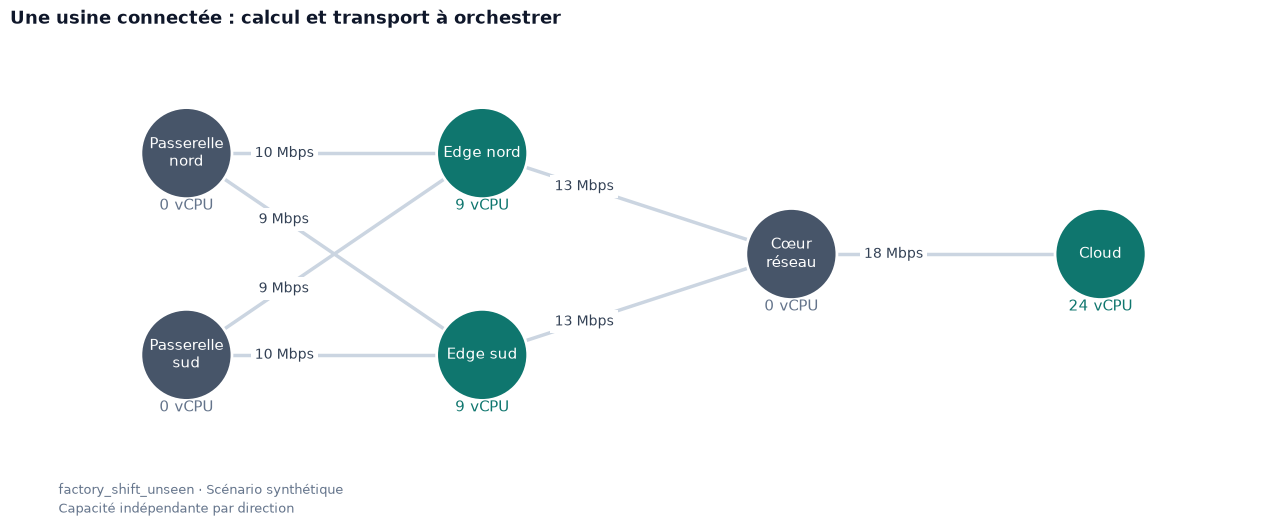

In [3]:
def network_layout(case):
    graph = nx.Graph()
    graph.add_nodes_from(n.id for n in case.nodes)
    graph.add_edges_from(
        (case.nodes[e.source].id, case.nodes[e.target].id) for e in case.links
    )
    demo_positions = {
        "gateway_north": (0, 1.4),
        "gateway_south": (0, -1.4),
        "edge_north": (2.2, 1.4),
        "edge_south": (2.2, -1.4),
        "core_switch": (4.5, 0),
        "cloud_dc": (6.8, 0),
    }
    positions = (
        demo_positions
        if set(graph) == set(demo_positions)
        else nx.spring_layout(graph, seed=42)
    )
    return graph, positions


def plot_network(case, decision=None, method=""):
    graph, positions = network_layout(case)
    fig, ax = plt.subplots(figsize=(13, 5.3))
    if decision is None:
        nx.draw_networkx_edges(graph, positions, ax=ax, edge_color="#cbd5e1", width=2.5)
    else:
        directed = {(e["source"], e["target"]): e for e in decision["directed_links"]}
        utilization = [
            max(directed[u, v]["load_mbps"], directed[v, u]["load_mbps"])
            / directed[u, v]["capacity_mbps"]
            for u, v in graph.edges
        ]
        nx.draw_networkx_edges(
            graph,
            positions,
            ax=ax,
            edge_color=utilization,
            edge_cmap=plt.cm.YlOrRd,
            edge_vmin=0,
            edge_vmax=1,
            width=[2 + 4 * ratio for ratio in utilization],
        )
    colors = [TEAL if n.cpu > 0 else "#475569" for n in case.nodes]
    nx.draw_networkx_nodes(
        graph,
        positions,
        ax=ax,
        node_color=colors,
        node_size=4300,
        edgecolors="white",
        linewidths=2,
    )
    names = {
        "gateway_north": "Passerelle\nnord",
        "gateway_south": "Passerelle\nsud",
        "edge_north": "Edge nord",
        "edge_south": "Edge sud",
        "core_switch": "Cœur\nréseau",
        "cloud_dc": "Cloud",
    }
    nx.draw_networkx_labels(
        graph,
        positions,
        ax=ax,
        labels={n.id: names.get(n.id, n.id.replace("_", "\n")) for n in case.nodes},
        font_color="white",
        font_size=10.5,
    )
    capacity_labels = {
        (case.nodes[e.source].id, case.nodes[e.target].id): f"{e.capacity_mbps:g} Mbps"
        for e in case.links
    }
    if decision is not None:
        capacity_labels = {
            (
                u,
                v,
            ): f"{max(directed[u, v]['load_mbps'], directed[v, u]['load_mbps']):g} / "
            f"{directed[u, v]['capacity_mbps']:g} Mbps"
            for u, v in graph.edges
        }
    nx.draw_networkx_edge_labels(
        graph,
        positions,
        ax=ax,
        edge_labels=capacity_labels,
        label_pos=0.32,
        rotate=False,
        font_size=10,
        font_color="#334155",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 3},
    )
    span = max(p[1] for p in positions.values()) - min(p[1] for p in positions.values())
    for node in case.nodes:
        x, y = positions[node.id]
        ax.text(
            x,
            y - max(span * 0.28, 0.40),
            f"{node.cpu:g} vCPU",
            ha="center",
            fontsize=11,
            color=TEAL if node.cpu > 0 else "#64748b",
        )
        if decision is not None:
            services = [
                p["service"] for p in decision["placements"] if p["node"] == node.id
            ]
            if services:
                ax.text(
                    x,
                    y + max(span * 0.28, 0.40),
                    "\n".join(services),
                    ha="center",
                    fontsize=9,
                    color=TEAL,
                    fontweight="bold",
                )
    ax.margins(x=0.13, y=0.40)
    title = (
        "Une usine connectée : calcul et transport à orchestrer"
        if decision is None
        else f"Placement des services et trafic réseau · {method}"
    )
    ax.set_title(title, loc="left", pad=22)
    ax.axis("off")
    note = (
        "Capacité indépendante par direction"
        if decision is None
        else "Charge affichée : maximum des deux directions · Rouge : lien davantage utilisé"
    )
    fig.text(
        0.05,
        0.02,
        f"{case.id} · Scénario synthétique\n{note}",
        fontsize=9,
        linespacing=1.5,
        color="#64748b",
    )
    fig.tight_layout(rect=(0, 0.10, 1, 1))
    return fig


demo = load_instance(ROOT / "instances/legacy/eval/factory_shift_unseen.json")
fig = plot_network(demo)
fig.savefig(ASSETS / "network.png", dpi=160)
plt.show()

## 3. Mesurer le trafic servi sur les scénarios fournis

La figure ci-dessous est reproductible sans entraînement PPO. Les dix scénarios
d'entraînement sont des cas de démonstration ; la dernière barre correspond au
scénario tenu à l'écart. Aucun score PPO n'est déduit des scores de la référence.
Le tableau conserve les valeurs absolues en Mbps et les statuts de faisabilité.


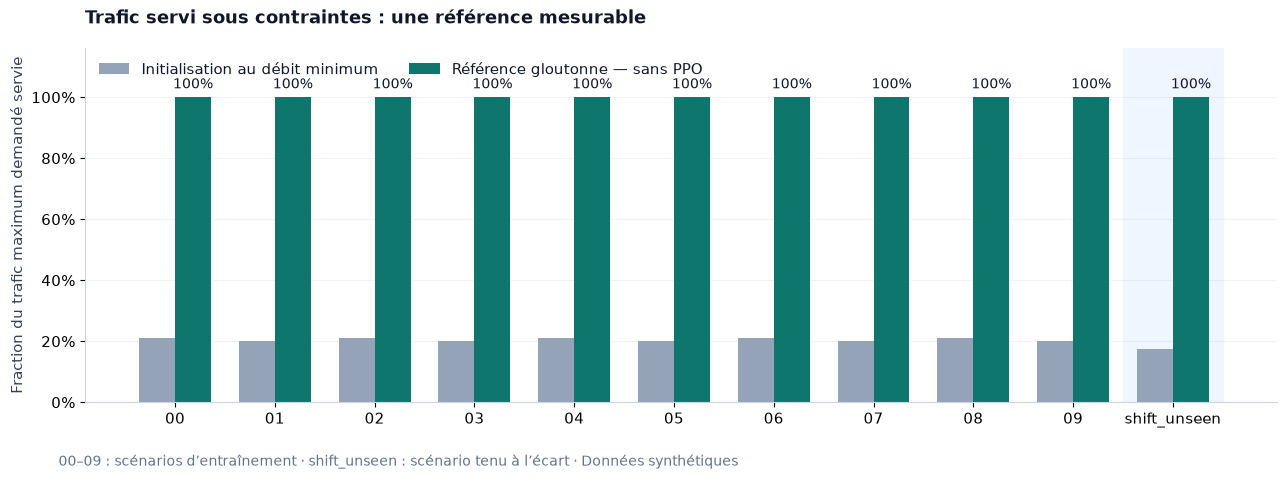

| Scénario | Jeu | Initialisation (Mbps) | Référence (Mbps) | Demandés (Mbps) | Servis | Faisable |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| factory_train_00 | train | 4 | 19 | 19 | 100.0% | True |
| factory_train_01 | train | 4 | 20 | 20 | 100.0% | True |
| factory_train_02 | train | 4 | 19 | 19 | 100.0% | True |
| factory_train_03 | train | 4 | 20 | 20 | 100.0% | True |
| factory_train_04 | train | 4 | 19 | 19 | 100.0% | True |
| factory_train_05 | train | 4 | 20 | 20 | 100.0% | True |
| factory_train_06 | train | 4 | 19 | 19 | 100.0% | True |
| factory_train_07 | train | 4 | 20 | 20 | 100.0% | True |
| factory_train_08 | train | 4 | 19 | 19 | 100.0% | True |
| factory_train_09 | train | 4 | 20 | 20 | 100.0% | True |
| factory_shift_unseen | eval | 4 | 23 | 23 | 100.0% | True |


In [4]:
files = sorted((ROOT / "instances/legacy/train").glob("*.json"))
files += [ROOT / "instances/legacy/eval/factory_shift_unseen.json"]
rows = []
for path in files:
    case, _, refs = references(path)
    initial, greedy = refs["Initialisation"], refs["Référence gloutonne"]
    rows.append(
        {
            "instance": case.id,
            "split": path.parent.name,
            "initial_mbps": initial["total_served_mbps"],
            "reference_mbps": greedy["total_served_mbps"],
            "requested_mbps": greedy["max_requested_mbps"],
            "initial_fraction": initial["served_fraction"],
            "reference_fraction": greedy["served_fraction"],
            "initial_feasible": initial["feasible"],
            "reference_feasible": greedy["feasible"],
        }
    )

x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.axvspan(9.5, 10.5, color="#eff6ff", zorder=0)
ax.bar(
    x - 0.18,
    [r["initial_fraction"] for r in rows],
    width=0.36,
    color=GRAY,
    label="Initialisation au débit minimum",
)
bars = ax.bar(
    x + 0.18,
    [r["reference_fraction"] for r in rows],
    width=0.36,
    color=TEAL,
    label="Référence gloutonne — sans PPO",
)
ax.bar_label(
    bars,
    labels=[f"{r['reference_fraction']:.0%}" for r in rows],
    padding=4,
    fontsize=10,
)
ax.set_xticks(
    x,
    [r["instance"].replace("factory_train_", "").replace("factory_", "") for r in rows],
)
ax.set_ylim(0, 1.16)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Fraction du trafic maximum demandé servie")
ax.set_title(
    "Trafic servi sous contraintes : une référence mesurable", loc="left", pad=18
)
ax.legend(loc="upper left", frameon=False, ncol=2)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
fig.text(
    0.05,
    0.015,
    "00–09 : scénarios d’entraînement · shift_unseen : scénario tenu à l’écart · Données synthétiques",
    fontsize=10,
    color="#64748b",
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(ASSETS / "efficiency.png", dpi=160)
plt.show()

table = "| Scénario | Jeu | Initialisation (Mbps) | Référence (Mbps) | Demandés (Mbps) | Servis | Faisable |\n"
table += "| --- | --- | ---: | ---: | ---: | ---: | --- |\n"
for row in rows:
    table += (
        f"| {row['instance']} | {row['split']} | {row['initial_mbps']:g} | "
        f"{row['reference_mbps']:g} | {row['requested_mbps']:g} | "
        f"{row['reference_fraction']:.1%} | {row['reference_feasible']} |\n"
    )
display(Markdown(table))

## 4. Comparer une politique PPO réellement entraînée (optionnel)

Activer `RUN_PPO = True` après `python train.py`. Le checkpoint doit contenir le
modèle, la normalisation et les métadonnées. La compatibilité de la topologie et
de l'inventaire est vérifiée. La référence est recalculée avec le même nombre de
chemins candidats que le checkpoint.

Le graphique compare le meilleur état faisable rencontré sur cinq épisodes
stochastiques par défaut à la référence déterministe. Le nombre d'épisodes et la
seed sont affichés : il s'agit d'un essai sur un scénario, pas d'une moyenne sur
plusieurs entraînements. Un écart négatif est conservé.


**PPO non évalué.** Les figures suivantes décrivent la référence gloutonne. Activer `RUN_PPO` pour ajouter une mesure issue du modèle.

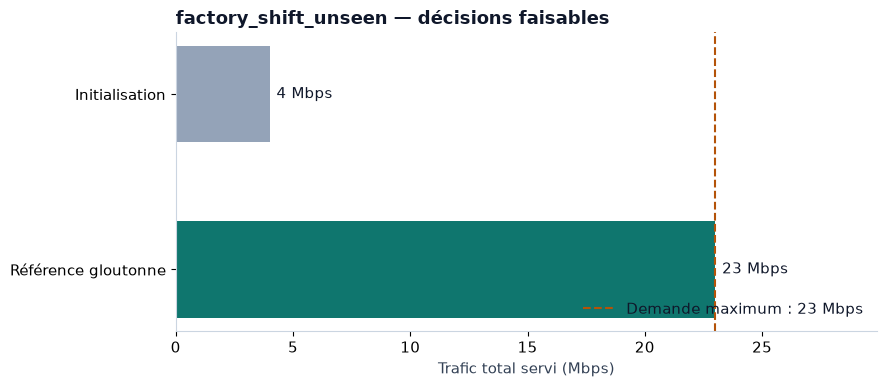

In [5]:
ppo_decision = None
if RUN_PPO:
    required = ["model.zip", "vecnormalize.pkl", "metadata.json"]
    missing = [name for name in required if not (CHECKPOINT / name).is_file()]
    if missing:
        raise FileNotFoundError(
            f"Checkpoint incomplet ({missing}). Exécuter python train.py."
        )
    metadata = json.loads((CHECKPOINT / "metadata.json").read_text(encoding="utf-8"))
    validate_compatible([problem], reference=metadata["signature"])
    problem, catalogue, decisions = references(INSTANCE_PATH, k=int(metadata["paths"]))
    output = ROOT / "outputs/notebook/decision.json"
    completed = subprocess.run(
        [
            sys.executable,
            "eval.py",
            "--checkpoint",
            str(CHECKPOINT),
            "--instance",
            str(INSTANCE_PATH),
            "--output",
            str(output),
            "--episodes",
            str(PPO_EPISODES),
            "--stochastic",
            "--seed",
            str(PPO_SEED),
        ],
        cwd=ROOT,
        check=True,
        capture_output=True,
        text=True,
    )
    ppo_decision = json.loads(output.read_text(encoding="utf-8"))
    if not ppo_decision["feasible"]:
        raise ValueError("La décision PPO doit être faisable.")
    reference_mbps = decisions["Référence gloutonne"]["total_served_mbps"]
    if ppo_decision["reference_greedy_mbps"] != reference_mbps:
        raise ValueError("La référence du notebook diffère de celle de eval.py.")
    decisions["PPO"] = ppo_decision
    delta = ppo_decision["total_served_mbps"] - reference_mbps
    display(
        Markdown(
            f"**PPO :** {ppo_decision['total_served_mbps']:g} Mbps ; "
            f"**écart à la référence : {delta:+g} Mbps**. "
            f"{PPO_EPISODES} épisodes stochastiques, seed {PPO_SEED}. "
            f"Checkpoint : {metadata['timesteps_actual']} pas d'entraînement, "
            f"seed d'entraînement {metadata['seed']}."
        )
    )
else:
    display(
        Markdown(
            "**PPO non évalué.** Les figures suivantes décrivent la référence gloutonne. "
            "Activer `RUN_PPO` pour ajouter une mesure issue du modèle."
        )
    )

names = list(decisions)
fig, ax = plt.subplots(figsize=(9, 4))
values = [decisions[name]["total_served_mbps"] for name in names]
bars = ax.barh(names, values, color=[GRAY, TEAL, BLUE][: len(names)], height=0.55)
ax.bar_label(bars, labels=[f"{v:g} Mbps" for v in values], padding=5)
requested = sum(d.max_mbps for d in problem.demands)
ax.axvline(
    requested,
    color=AMBER,
    linestyle="--",
    label=f"Demande maximum : {requested:g} Mbps",
)
ax.set_xlim(0, requested * 1.30)
ax.set_xlabel("Trafic total servi (Mbps)")
ax.set_title(f"{problem.id} — décisions faisables", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## 5. Inspecter les ressources et les budgets de latence

Ces graphiques décrivent PPO si une évaluation vient d'être effectuée, sinon la
référence gloutonne. Chaque direction d'un lien est affichée séparément.
Les nœuds à 0 vCPU sont exclus du ratio CPU (ils ne peuvent héberger les services
du démonstrateur). Une utilisation de 100 % signifie que la capacité ou le budget
est atteint, **sans le dépasser** ; ce n'est pas un objectif à maximiser.


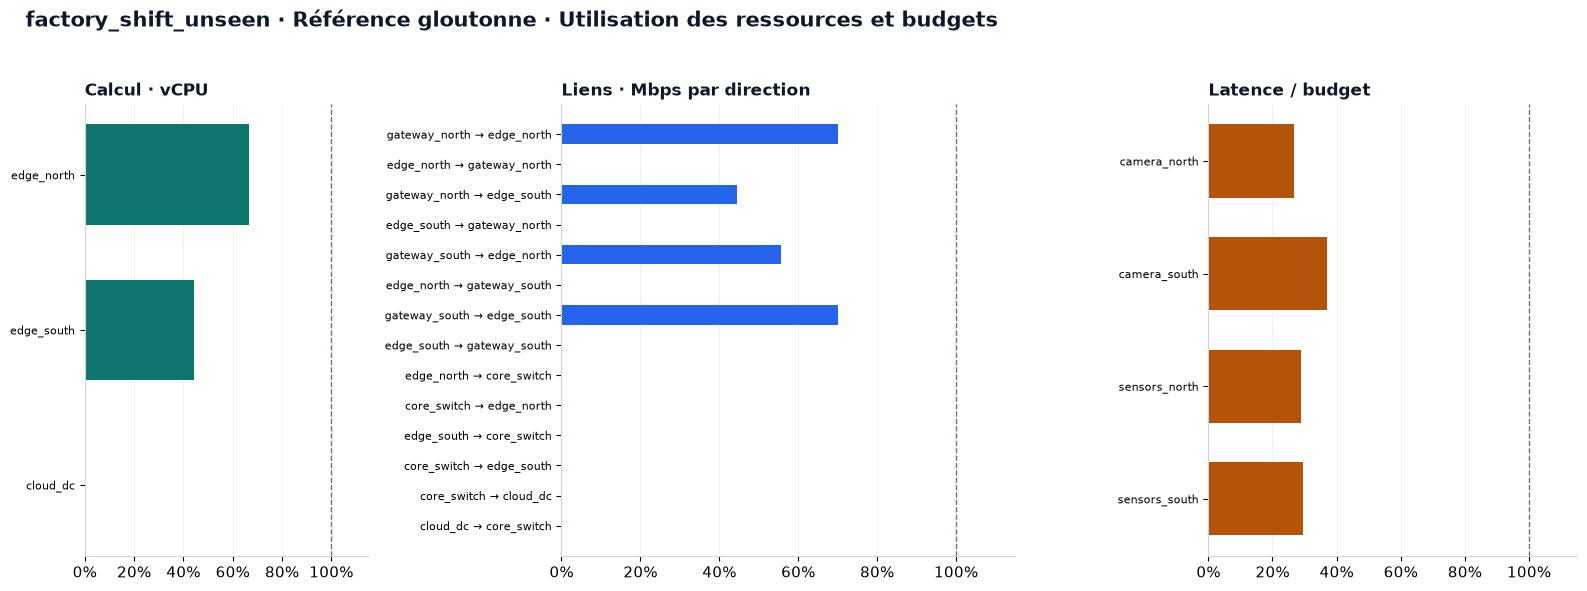

| Service | Placement | vCPU |
| --- | --- | ---: |
| video_analytics | edge_north | 6 |
| machine_telemetry | edge_south | 4 |


| Demande | Route | Mbps servis / maximum | Latence / budget (ms) |
| --- | --- | ---: | ---: |
| camera_north | gateway_north → edge_north | 7 / 7 | 2.66 / 10 |
| camera_south | gateway_south → edge_north | 5 / 5 | 3.70 / 10 |
| sensors_north | gateway_north → edge_south | 4 / 4 | 3.48 / 12 |
| sensors_south | gateway_south → edge_south | 7 / 7 | 2.66 / 9 |


In [6]:
selected_name = "PPO" if ppo_decision is not None else "Référence gloutonne"
selected = decisions[selected_name]

fig, axes = plt.subplots(
    1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.6, 1.3]}
)
cpu = [n for n in selected["node_compute_loads"] if n["available_vcpu"] > 0]
links = selected["directed_links"]
demands = selected["demands"]
panels = [
    (
        axes[0],
        [n["node"] for n in cpu],
        [n["used_vcpu"] / n["available_vcpu"] for n in cpu],
        "Calcul · vCPU",
        TEAL,
    ),
    (
        axes[1],
        [f"{e['source']} → {e['target']}" for e in links],
        [e["load_mbps"] / e["capacity_mbps"] for e in links],
        "Liens · Mbps par direction",
        BLUE,
    ),
    (
        axes[2],
        [d["demand"] for d in demands],
        [d["latency_ms"] / d["latency_budget_ms"] for d in demands],
        "Latence / budget",
        AMBER,
    ),
]
for ax, labels, values, title, color in panels:
    ax.barh(labels, values, color=color, height=0.65)
    ax.axvline(1, color="#64748b", linestyle="--", linewidth=1)
    ax.set_xlim(0, max(1.15, max(values, default=0) * 1.12))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(title, fontsize=12, loc="left")
    ax.tick_params(axis="y", labelsize=8)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle(
    f"{problem.id} · {selected_name} · Utilisation des ressources et budgets",
    x=0.02,
    ha="left",
    fontsize=15,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
output_dir = ROOT / "outputs/notebook"
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / "resource_usage.png", dpi=160)
plt.show()

placement_table = "| Service | Placement | vCPU |\n| --- | --- | ---: |\n"
for p in selected["placements"]:
    placement_table += f"| {p['service']} | {p['node']} | {p['cpu_vcpu']:g} |\n"
display(Markdown(placement_table))
route_table = "| Demande | Route | Mbps servis / maximum | Latence / budget (ms) |\n| --- | --- | ---: | ---: |\n"
for d in demands:
    route_table += (
        f"| {d['demand']} | {' → '.join(d['route'])} | "
        f"{d['quantity_mbps']} / {d['max_mbps']} | "
        f"{d['latency_ms']:.2f} / {d['latency_budget_ms']:g} |\n"
    )
display(Markdown(route_table))

## 6. Visualiser la décision sur le réseau

La couleur et l'épaisseur des liens représentent le maximum d'utilisation de leurs
deux directions, et non leur somme. Le détail par direction reste dans le graphique
précédent. Les noms des services sont annotés au-dessus du nœud où ils sont placés.


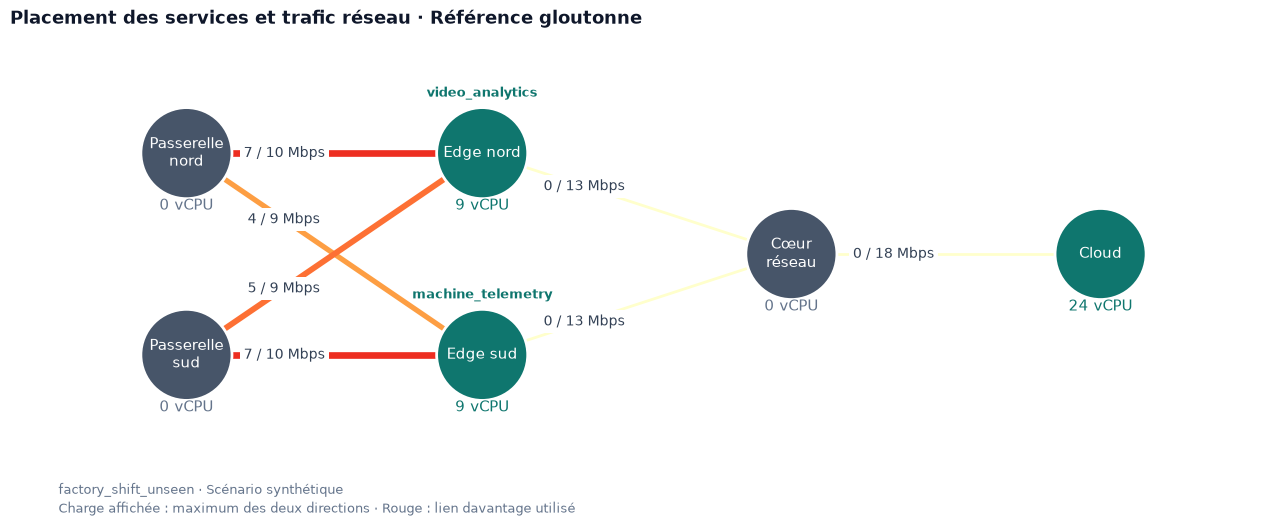

In [7]:
fig = plot_network(problem, decision=selected, method=selected_name)
fig.savefig(output_dir / "selected_network.png", dpi=160)
plt.show()


# Figure publiée : référence déterministe sur le scénario fourni, même si PPO
# ou un autre scénario est sélectionné pour les graphiques exploratoires.
_, _, demo_decisions = references(
    ROOT / "instances/legacy/eval/factory_shift_unseen.json", k=K_PATHS
)
fig = plot_network(
    demo,
    decision=demo_decisions["Référence gloutonne"],
    method="Référence gloutonne — sans PPO",
)
fig.savefig(ASSETS / "decision_network.png", dpi=160)
plt.close(fig)

## 7. Conserver la provenance des figures

`network.png` et `decision_network.png` alimentent le README : topologie et exemple
de décision de la référence gloutonne. `efficiency.png` conserve la comparaison
des références sur les 11 scénarios pour une exploration séparée.
Le manifeste conserve les empreintes des scénarios, les versions des bibliothèques
et les scores calculés.

Ces trois figures utilisent exclusivement les scénarios fournis et les références
déterministes ; elles restent indépendantes de l'activation de PPO et du scénario
sélectionné. Les résultats PPO et les vues de la décision sélectionnée restent
dans `outputs/notebook/`.


In [8]:
provenance = {
    "schema_version": 1,
    "figures": ["network.png", "decision_network.png", "efficiency.png"],
    "methods": [
        "minimum-Mbps feasible seed",
        "greedy uplift with fixed placement/routes",
    ],
    "ppo_in_readme_figures": False,
    "paths": K_PATHS,
    "units": {"flow": "Mbps", "compute": "vCPU", "latency": "ms"},
    "source_sha256": {
        path.relative_to(ROOT).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
        for path in files
    },
    "versions": {
        name: importlib.metadata.version(name)
        for name in ["numpy", "networkx", "matplotlib"]
    },
    "results": rows,
}
(ASSETS / "plot_provenance.json").write_text(
    json.dumps(provenance, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
)
print(
    "Figures exportées : docs/assets/network.png, decision_network.png et efficiency.png"
)
print("Provenance : docs/assets/plot_provenance.json")

Figures exportées : docs/assets/network.png, decision_network.png et efficiency.png
Provenance : docs/assets/plot_provenance.json


## Interpréter les résultats

- Un débit supérieur à l'initialisation montre une amélioration au-delà des demandes minimum.
- Un score PPO supérieur à la référence sur un scénario décrit ce seul essai ; il faut
  varier les seeds d'entraînement et les scénarios pour conclure sur les performances.
- Une saturation d'un lien ou d'un budget de latence peut limiter le débit même si du
  CPU reste disponible. La référence conserve ses placements/routes : elle peut laisser
  des possibilités d'amélioration par un autre placement ou routage.
- Le respect des contraintes concerne le modèle fourni. La généralisation aux données
  opérateur et l'application des décisions au réseau doivent être validées séparément.

[Présentation du projet](../README.md) · [Guide technique](../docs/technical-guide.md)
